# Разведочный анализ реальных витрин 1С:Университет

Источник данных: HTTP-сервис расширения АР_АналитикаРиска, опубликованный на
локальной базе 1С:Университет ПРОФ (УниверситетПРОФ_2_2, версия 2.3.2.28).
Витрины выгружены приемником src/onec_client/load.py с курсорной пагинацией
28.11.2026; слой cleaned содержит реальные данные вместо синтетики, наборы
UCI и OULAD не затронуты.

Правила персональных данных при приеме: номер зачетной книжки хранится только
псевдонимом book_hash (sha256 с солью, тот же алгоритм, что и для логина
Moodle), дата рождения заменена возрастом, ФИО и контакты витринами не
отдаются, связь записей только по идентификаторам.

Цель анализа: объемы и периоды реальных витрин, распределения для будущих
признаков, ограничения данных (финансы, дата внесения записей, числовые
отметки).

In [1]:
import sys, os
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.chdir(ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from utils.db import engine

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
eng = engine()

In [2]:
# Объемы витрин cleaned после замены синтетики реальными данными
tables = ['vs_students', 'vs_programs', 'vs_disciplines', 'vs_movements',
          'vs_grades', 'vs_debts', 'vs_load', 'vs_finance', 'vs_admission']
counts = {t: pd.read_sql(f'SELECT count(*) AS n FROM cleaned.{t}', eng)['n'].iloc[0]
          for t in tables}
print(pd.Series(counts, name='строк').to_string())
print()
print('finance: в этой базе данных оплат нет, источник будет в базе бухгалтерии')
print('admission: вступительные испытания витриной расширения не отдаются')

vs_students        13336
vs_programs         3303
vs_disciplines    275278
vs_movements      131649
vs_grades         617597
vs_debts           53220
vs_load             8865
vs_finance             0
vs_admission           0

finance: в этой базе данных оплат нет, источник будет в базе бухгалтерии
admission: вступительные испытания витриной расширения не отдаются


## 1. Студенты и контингент

Студенты взяты срезом регистра СостояниеСтудентов на дату выгрузки. Действующие
состояния те же, что использует существующая обработка синхронизации с Moodle:
«Является студентом» и «Задолжник». Состояния слушателей дополнительного
образования попадают в витрину вместе со студентами и учитываются отдельно.

In [3]:
students = pd.read_sql(
    "SELECT student_id, program_id, group_code, faculty, study_form, basis, gender,"
    " age, region, hostel, privilege, state, admission_date FROM cleaned.vs_students", eng)
students['active'] = students['state'].str.lower().isin(['является студентом', 'задолжник'])
print('всего записей студентов:', len(students))
print('действующих:', int(students['active'].sum()), f"({students['active'].mean():.1%})")
print('с датой зачисления из приказов:', int(students['admission_date'].notna().sum()))
print()
print(students['state'].value_counts().to_string())

всего записей студентов: 13336
действующих: 1702 (12.8%)
с датой зачисления из приказов: 13023

state
является выпускником                 3948
Отчислен слушатель                   3534
Отчислен обучающийся ПК/ШАХТ         1611
Отчислен                             1493
Является студентом                   1224
Является слушателем                   695
Задолжник                             478
Является обучающимся ПК/ШАХТ          328
Находится в академическом отпуске      25


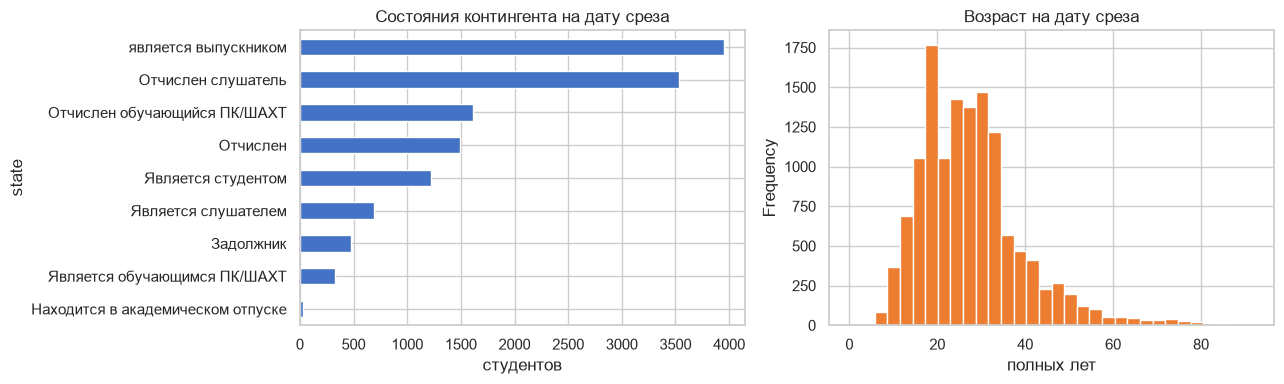

study_form
очная           9637
очно-заочная    3567
заочная          132

basis
полное возмещение затрат    9035
бюджетная основа            4079
целевой прием                104
Имеющие особое право          22
Места для Крыма                1


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
students['state'].value_counts().sort_values().plot.barh(ax=axes[0], color='#4472c4')
axes[0].set_title('Состояния контингента на дату среза')
axes[0].set_xlabel('студентов')
students.loc[students['age'].notna(), 'age'].plot.hist(bins=32, ax=axes[1], color='#ed7d31')
axes[1].set_title('Возраст на дату среза')
axes[1].set_xlabel('полных лет')
plt.tight_layout()
plt.show()

print(students['study_form'].value_counts().to_string())
print()
print(students['basis'].value_counts().to_string())

## 2. Программы и нагрузка

Программа подготовки это документ учебного плана: наименование специальности,
форма обучения и учебный год. Нагрузка план-семестр содержит число дисциплин,
часы и зачетные единицы семестра (из части ЗЕТПоДисциплинам, при отсутствии
вычисленные по норме часов).

In [5]:
programs = pd.read_sql('SELECT program_id, title, faculty, study_form, year, hours_per_credit FROM cleaned.vs_programs', eng)
load = pd.read_sql('SELECT program_id, semester, n_disciplines, hours, n_exams, n_tests, n_course_projects, credits, credits_source FROM cleaned.vs_load', eng)
print('программ (документов планов):', len(programs))
print('строк нагрузки план-семестр:', len(load))
print('планов с записями дисциплин:', programs['program_id'].isin(load['program_id']).sum())
print('норма часов в зачетной единице:', programs['hours_per_credit'].value_counts().head().to_dict())
print('источник зачетных единиц:', load['credits_source'].value_counts().to_dict())
print()
pivot = load[load['semester'].between(1, 12)].groupby('semester')['credits'].mean().round(1)
print(pivot.to_string())

программ (документов планов): 3303
строк нагрузки план-семестр: 8865
планов с записями дисциплин: 2827
норма часов в зачетной единице: {36: 3301, 40: 2}
источник зачетных единиц: {'plan': 8729, 'calculated': 136}

semester
1.0     28.9
2.0     34.8
3.0     28.7
4.0     32.9
5.0     30.0
6.0     35.0
7.0     31.3
8.0     33.9
9.0     35.0
10.0    34.8
11.0    26.2
12.0    39.6


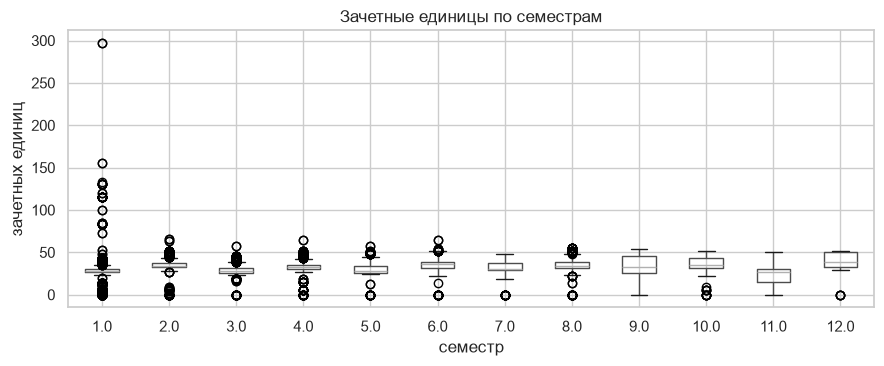

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
load[load['semester'].between(1, 12)].boxplot(column='credits', by='semester', ax=ax, grid=True)
ax.set_title('Зачетные единицы по семестрам')
ax.set_xlabel('семестр')
ax.set_ylabel('зачетных единиц')
plt.suptitle('')
plt.tight_layout()
plt.show()

## 3. Дисциплины учебных планов

Строки планов: дисциплина семестра с видом нагрузки и количеством часов,
зачетные единицы по узлу дисциплины. Вид нагрузки берется из справочников
видов контроля и видов нагрузки по наименованию.

In [7]:
disciplines = pd.read_sql(
    'SELECT discipline_id, title, program_id, semester, control_type, credits FROM cleaned.vs_disciplines', eng)
print('строк планов с дисциплиной:', len(disciplines))
print('уникальных дисциплин:', disciplines['discipline_id'].nunique())
print('семестров, покрытых планами:', sorted(disciplines['semester'].dropna().unique().astype(int)))
print()
print(disciplines['control_type'].value_counts().head(15).to_string())

строк планов с дисциплиной: 275278
уникальных дисциплин: 849
семестров, покрытых планами: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

control_type
Практические занятия                        68865
Зачет с оценкой                             37027
Самостоятельная работа                      35824
Лекции                                      32753
Секретарь ГЭК                               27136
Зачет                                       25498
Экзамен                                     15891
Текущий контроль 0,5                         9636
Текущий контроль 1,0                         7655
Курсовой проект                              5034
Курсовая работа                              2162
Производственная практика                    2049
Учебная практика                             1760
Защита выпускной квалификационной работы     1032
Курсовой проект 2     

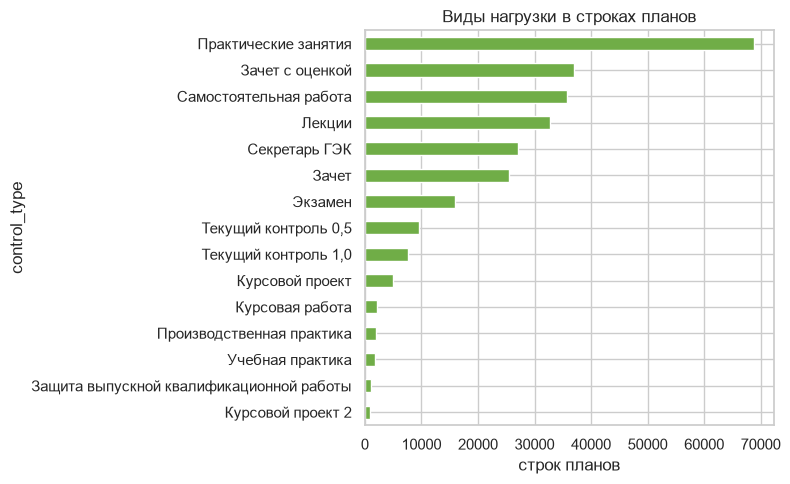

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
disciplines['control_type'].value_counts().head(15).sort_values().plot.barh(ax=ax, color='#70ad47')
ax.set_title('Виды нагрузки в строках планов')
ax.set_xlabel('строк планов')
plt.tight_layout()
plt.show()

## 4. Оценки

Оценки это строки ведомостей с историей попыток: номер попытки присваивается
по порядку ведомостей одного ключа студент, план, дисциплина, период контроля.
Отметки в основном именованные (Отлично, Хорошо, Зачтено, Неявка и другие);
числовые отметки стобалльной шкалы составляют около 5% строк полной истории
и идут ведомостями без периода контроля. Порог неудовлетворительной отметки
40 баллов утвержден заказчиком 28.11.2026 и применяется расширением при выводе
задолженностей: числа ниже 40 открывают задолженность, 40 и выше считаются
положительными.

In [9]:
grades = pd.read_sql(
    "SELECT student_id, program_id, discipline_id, semester, control_type, attempt_no,"
    " grade, absent, exam_date, grade_numeric, is_pass FROM cleaned.vs_grades", eng,
    parse_dates=['exam_date'])
grades['year'] = grades['exam_date'].dt.year
print('оценок:', len(grades))
print('студентов с оценками:', grades['student_id'].nunique())
print('дисциплин:', grades['discipline_id'].nunique())
print('период:', grades['exam_date'].min().date(), '-', grades['exam_date'].max().date())
print('доля неявок:', f"{grades['absent'].mean():.1%}")
print('доля пересдач (попытка 2 и далее):', f"{(grades['attempt_no'] >= 2).mean():.1%}")
print('доля положительных:', f"{grades['is_pass'].mean():.1%}")
print()
print(grades['grade'].value_counts().head(12).to_string())

оценок: 617597
студентов с оценками: 10881
дисциплин: 635
период: 2012-12-24 - 2026-12-30
доля неявок: 12.4%
доля пересдач (попытка 2 и далее): 17.5%
доля положительных: 85.5%



grade
Отлично                180914
Зачтено                154365
Хорошо                 120272
Неявка                  76631
Удовлетворительно       45454
Не зачтено               2659
Неудовлетворительно      1886
40                       1660
80                       1630
60                       1614
70                       1596
50                       1579


числовых отметок: 31630 (5.1% строк)
диапазон числовых отметок: 0 - 100
из них отрицательных, ниже 40: 4769
ведомостей без периода контроля: 31631



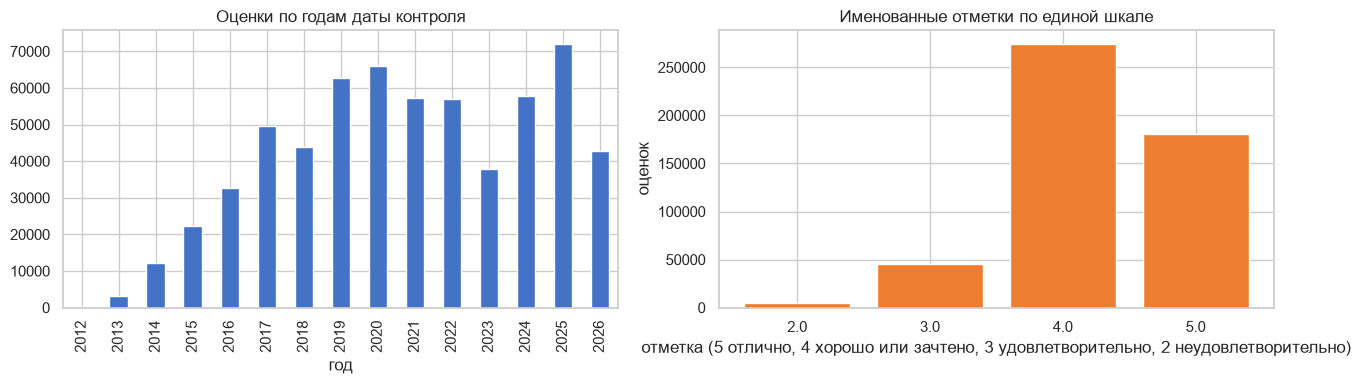

In [10]:
numeric_marks = grades.loc[grades['grade'].str.fullmatch(r'\d+', na=False), 'grade'].astype(int)
print('числовых отметок:', len(numeric_marks), f"({len(numeric_marks) / len(grades):.1%} строк)")
if len(numeric_marks):
    print('диапазон числовых отметок:', int(numeric_marks.min()), '-', int(numeric_marks.max()))
    print('из них отрицательных, ниже 40:', int((numeric_marks < 40).sum()))
print('ведомостей без периода контроля:', int(grades['semester'].isna().sum()))
print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
grades.groupby('year').size().plot.bar(ax=axes[0], color='#4472c4')
axes[0].set_title('Оценки по годам даты контроля')
axes[0].set_xlabel('год')
named = grades.loc[grades['grade_numeric'].notna(), 'grade_numeric'].value_counts().sort_index()
axes[1].bar(named.index.astype(str), named.values, color='#ed7d31')
axes[1].set_title('Именованные отметки по единой шкале')
axes[1].set_xlabel('отметка (5 отлично, 4 хорошо или зачтено, 3 удовлетворительно, 2 неудовлетворительно)')
axes[1].set_ylabel('оценок')
plt.tight_layout()
plt.show()

## 5. Задолженности

Задолженность выводится расширением из ведомостей: отрицательная отметка
(Неудовлетворительно, Не зачтено, Неявка, число ниже 40 баллов) открывает
задолженность, следующая положительная отметка по тому же ключу студент,
план, дисциплина, период контроля закрывает. Служебные отметки ведомостей
состояния загрузки работ не открывают и не закрывают задолженность.

In [11]:
debts = pd.read_sql(
    "SELECT student_id, discipline_id, semester, arose_date, closed_date, is_closed, days_open"
    " FROM cleaned.vs_debts", eng, parse_dates=['arose_date', 'closed_date'])
debts['year'] = debts['arose_date'].dt.year
print('задолженностей всего:', len(debts))
print('открытых (не закрытых):', int((~debts['is_closed']).sum()))
print('студентов с задолженностями:', debts['student_id'].nunique())
print()
print(debts['days_open'].describe().round(1).to_string())

задолженностей всего: 53220
открытых (не закрытых): 27859
студентов с задолженностями: 6295

count     25361.0
mean        370.3
std       12824.5
min           0.0
25%          51.0
50%         124.0
75%         184.0
max      730639.0


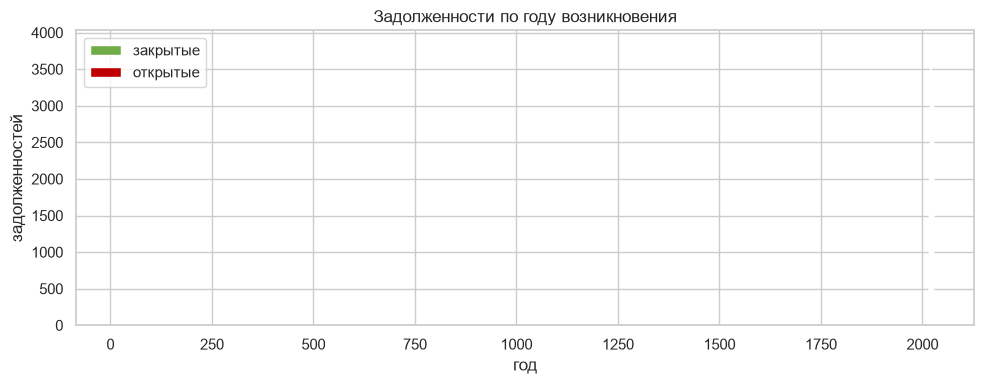

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
closed_by_year = debts[debts['is_closed']].groupby('year').size()
open_by_year = debts[~debts['is_closed']].groupby('year').size()
idx = sorted(set(closed_by_year.index) | set(open_by_year.index))
ax.bar([i - 0.2 for i in idx], [closed_by_year.get(i, 0) for i in idx], width=0.4, label='закрытые', color='#70ad47')
ax.bar([i + 0.2 for i in idx], [open_by_year.get(i, 0) for i in idx], width=0.4, label='открытые', color='#c00000')
ax.set_title('Задолженности по году возникновения')
ax.set_xlabel('год')
ax.set_ylabel('задолженностей')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Движения контингента и классификация отчислений

Строки приказов классифицированы приемником по утвержденному делению аналитики
(metadata-mapping.md, п. 4): академические (за академическую неуспеваемость,
невыполнение учебного плана, как не прошедших ГИА), финансовые (невыполнение
условий договора), остальные нейтральные. Отчисления слушателей дополнительного
образования идут другими типами приказов и в студенческие отчисления не
включаются.

In [13]:
movements = pd.read_sql(
    "SELECT student_id, order_type, order_kind, analytics, order_date, effective_date,"
    " order_class FROM cleaned.vs_movements", eng, parse_dates=['effective_date'])
print('строк приказов:', len(movements))
print('период:', movements['effective_date'].min().date(), '-', movements['effective_date'].max().date())
print()
print(movements['order_type'].value_counts().head(12).to_string())
print()
expulsions = movements[movements['order_type'] == 'Отчисление']
print('отчислений студентов (тип Отчисление):', len(expulsions))
print(expulsions['order_class'].value_counts().to_string())

строк приказов: 131649
период: 2012-01-01 - 2026-11-26

order_type
Утверждение тем работ                              35744
Перевод на следующий курс                          13536
Зачисление на дополнительное образование           11588
Практика                                            8481
Зачисление в вуз                                    7978
Продление срока погашения задолжности               7132
Отчисление (выпуск) дополнительного образования     6062
Перевод на следующий курс условно                   6027
Перевод                                             5445
Выпуск                                              4505
Считать переведенным (после условного)              4409
Отчисление (выпуск) ШАХТ                            3878

отчислений студентов (тип Отчисление): 2560
order_class
нейтральное      1821
академическое     712
финансовое         27


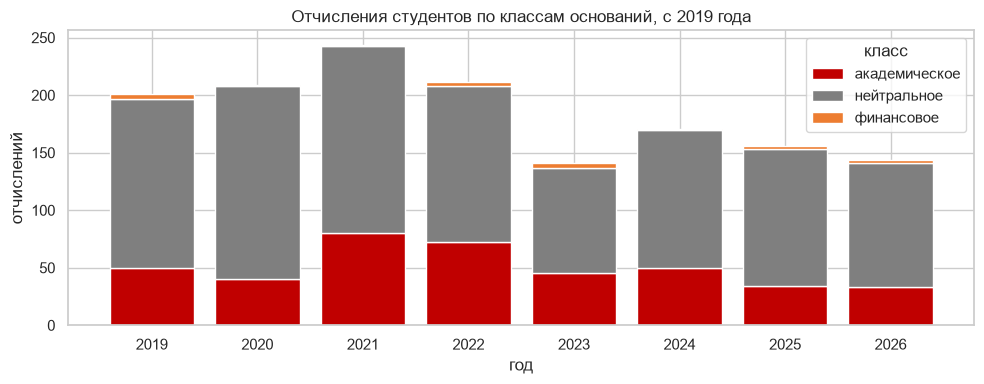

In [14]:
recent = expulsions[expulsions['effective_date'].dt.year >= 2019]
table = recent.pivot_table(index='effective_date', columns='order_class',
                           values='student_id', aggfunc='count').resample('YE').sum()
table.index = table.index.year
colors = {'академическое': '#c00000', 'финансовое': '#ed7d31', 'нейтральное': '#7f7f7f'}
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(table))
for cls in table.columns:
    ax.bar(table.index, table[cls], bottom=bottom, label=cls, color=colors.get(cls, '#4472c4'))
    bottom += table[cls].fillna(0).values
ax.set_title('Отчисления студентов по классам оснований, с 2019 года')
ax.set_xlabel('год')
ax.set_ylabel('отчислений')
ax.legend(title='класс')
plt.tight_layout()
plt.show()

## 7. Ограничения данных

Сводка ограничений, важных для признаков и модели:
витрина finance пустая (оплаты в этой базе данных не проводятся, источник
будет в базе бухгалтерии), дата внесения записей в источниках отсутствует,
поэтому срез на дату наблюдения дополняется запаздыванием на приемнике;
реквизиты региона, общежития и льгот в источниках не ведутся; числовые
отметки стобалльной шкалы редки.

In [15]:
checks = {
    'оплат в витрине finance': 0,
    'строк admission': 0,
    'студентов с регионом': int(students['region'].notna().sum()),
    'студентов с общежитием или льготой': int(students[['hostel', 'privilege']].notna().any(axis=1).sum()),
    'числовых отметок': len(numeric_marks),
    'оценок без периода контроля': int(grades['semester'].isna().sum()),
}
print(pd.Series(checks, name='значений').to_string())
print()
active_share = students['active'].mean()
print(f'Действующий контингент на дату среза: {active_share:.1%} записей')

оплат в витрине finance                   0
строк admission                           0
студентов с регионом                      0
студентов с общежитием или льготой        0
числовых отметок                      31630
оценок без периода контроля           31631

Действующий контингент на дату среза: 12.8% записей


## Выводы

1. Реальные витрины замещают синтетику в cleaned: контингент на дату среза,
   планы с дисциплинами и нагрузкой, ведомости с историей попыток и
   задолженности покрывают многолетний период работы базы.
2. Состояния контингента различаются по составу: действующие студенты и
   задолжники, выпускники, отчисленные, академические отпуска и слушатели
   дополнительного образования; для признаков действующие состояния те же,
   что в обработке синхронизации с Moodle.
3. Оценки преимущественно именованные; числовые отметки стобалльной шкалы
   составляют около 5% полной истории и идут ведомостями без периода
   контроля. Порог 40 баллов делит их на отрицательные и положительные
   на реальных данных, а не только на будущих выгрузках.
4. Задолженности многолетние: часть открыта и не закрыта, распределение
   времени закрытия длинное, что подтверждает значимость признака открытых
   долгов.
5. Отчисления студентов делятся по аналитике на академические, финансовые и
   нейтральные; деление утверждено заказчиком и переносится в целевую
   переменную при построении признаков на реальных данных.
6. Ограничения зафиксированы: финансов нет до подключения базы бухгалтерии,
   дата внесения записей отсутствует (запаздывание на приемнике), вступительные
   испытания и реквизиты региона, общежития и льгот в источниках не ведутся.